<a href="https://colab.research.google.com/github/ronjaladhikari213/AI-related-projects/blob/main/FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import torch
import torch.nn as nn
import pandas as pd
from sklearn.model_selection import train_test_split
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

In [31]:
torch.manual_seed(42)

In [32]:
df=pd.read_csv("fmnist_small.csv")
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,pixel11,pixel12,pixel13,pixel14,pixel15,pixel16,pixel17,pixel18,pixel19,pixel20,pixel21,pixel22,pixel23,pixel24,pixel25,pixel26,pixel27,pixel28,pixel29,pixel30,pixel31,pixel32,pixel33,pixel34,pixel35,pixel36,pixel37,pixel38,pixel39,...,pixel745,pixel746,pixel747,pixel748,pixel749,pixel750,pixel751,pixel752,pixel753,pixel754,pixel755,pixel756,pixel757,pixel758,pixel759,pixel760,pixel761,pixel762,pixel763,pixel764,pixel765,pixel766,pixel767,pixel768,pixel769,pixel770,pixel771,pixel772,pixel773,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,125,72,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,3,0,2,0,0,210,228,228,233,0,0,0,0,0,0,0,0,0,31,81,133,184,201,190,117,0,0,2,1,0,7,0,50,205,196,213,165,0,0
1,7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,43,117,34,15,24,33,117,80,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,51,144,152,...,157,158,161,148,159,58,0,6,0,0,0,0,0,0,0,0,0,4,0,60,143,143,148,146,152,152,148,148,147,145,142,142,142,21,0,3,0,0,0,0
3,8,0,0,0,0,0,0,0,0,0,0,0,0,2,0,33,114,37,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...,11,17,13,13,11,10,7,5,5,5,7,0,0,0,1,0,0,41,69,88,86,94,106,114,118,47,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,8,0,0,0,0,0,0,0,0,0,0,2,0,58,145,114,10,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,...,165,153,155,134,143,172,215,62,0,0,0,0,0,0,0,0,10,190,178,194,209,211,209,205,211,215,213,217,225,228,213,203,174,151,188,10,0,0,0,0


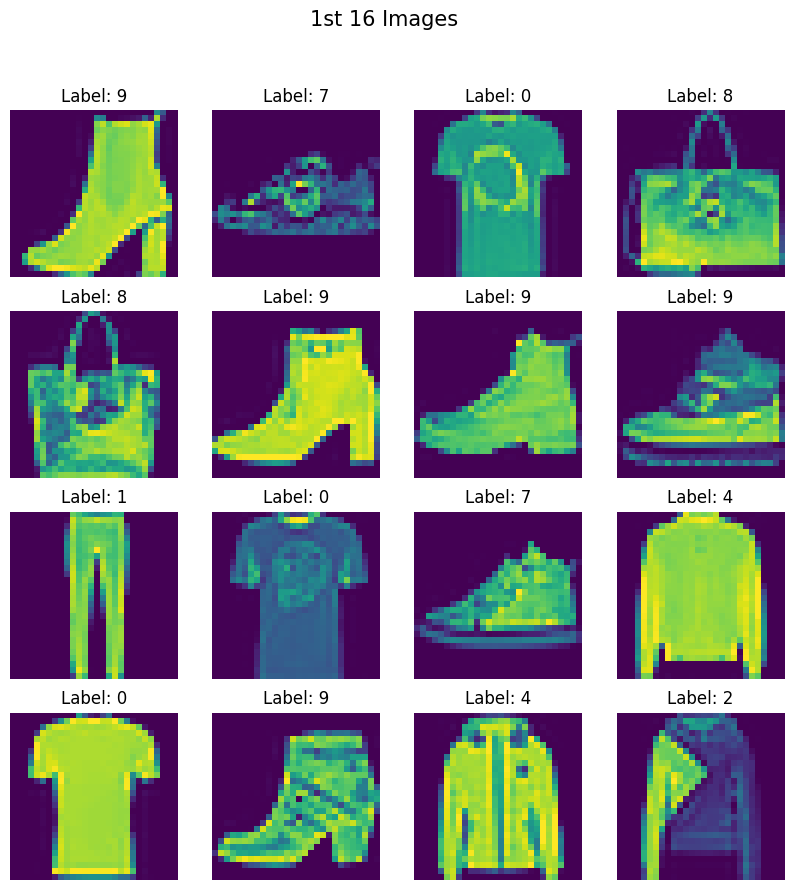

In [33]:
fig, axes = plt.subplots(4,4, figsize=(10,10))
fig.suptitle("1st 16 Images",fontsize=15)

for i, ax in enumerate(axes.flat):
  img= df.iloc[i,1:].values.reshape(28,28)
  ax.imshow(img)
  ax.axis('off')
  ax.set_title(f"Label: {df.iloc[i,0]}")
plt.show()

In [34]:
X = df.iloc[:,1:].values
y = df.iloc[:,0].values

In [35]:
X_train,X_test,y_train,y_test = train_test_split(X , y , test_size=0.2, random_state=42)

In [36]:
X_train = X_train/255.0
X_test = X_test/255.0

In [37]:
X_train = torch.tensor(X_train)
X_test = torch.tensor(X_test)
y_train = torch.tensor(y_train)
y_test = torch.tensor(y_test)

In [38]:
class CustomDataset(Dataset):
  def __init__(self,X,y):
    self.features = X.to(dtype=torch.float32)
    self.labels = y.to(dtype=torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self,index):
    return self.features[index], self.labels[index]

In [39]:
train_dataset = CustomDataset(X_train,y_train)
test_dataset = CustomDataset(X_test,y_test)

In [40]:
train_dataloader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32,shuffle=False)

In [41]:
class MyNN(nn.Module):

  def __init__(self, num_features):

    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )

  def forward(self, x):

    return self.model(x)

In [42]:
lr=0.01
epochs=1000

In [43]:
from torch.optim import optimizer
model=MyNN(X_train.shape[1])

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=lr)

In [45]:
for epoch in range(epochs):
  total_epoch_loss = 0
  for batch_features,batch_labels in train_dataloader:
    y_pred = model(batch_features)
    loss = criterion(y_pred,batch_labels)

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    total_epoch_loss += loss.item()

  avg_loss = total_epoch_loss/len(train_dataloader)
  print(f"Epoch: {epoch+1}, Loss: {avg_loss}")



Streaming output truncated to the last 5000 lines.
Epoch: 967, Loss: 0.0006107942771632224
Epoch: 967, Loss: 0.0006162431696429848
Epoch: 967, Loss: 0.000617563680668051
Epoch: 967, Loss: 0.0006218635007583847
Epoch: 967, Loss: 0.0006356405462914457
Epoch: 967, Loss: 0.0006400929794957241
Epoch: 967, Loss: 0.0006416408946582426
Epoch: 967, Loss: 0.0006479295110329986
Epoch: 967, Loss: 0.000655153455833594
Epoch: 967, Loss: 0.0006603529203372697
Epoch: 967, Loss: 0.0006630571213706086
Epoch: 967, Loss: 0.0006684444887408366
Epoch: 967, Loss: 0.0006720672536175698
Epoch: 967, Loss: 0.0006777877729230871
Epoch: 967, Loss: 0.0006875566109859695
Epoch: 967, Loss: 0.0006953376558764527
Epoch: 967, Loss: 0.0007013368078817924
Epoch: 967, Loss: 0.0007074067116870235
Epoch: 967, Loss: 0.0007139084915009638
Epoch: 967, Loss: 0.0007172657204015801
Epoch: 967, Loss: 0.0007243301451671869
Epoch: 967, Loss: 0.0007320738882602503
Epoch: 967, Loss: 0.0007403679615041862
Epoch: 967, Loss: 0.00075083845

In [46]:
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [47]:
total = 0
correct = 0

for batch_features, batch_labels in test_dataloader:
  y_pred = model(batch_features)
  _, predicted = torch.max(y_pred,1)
  total = total + batch_labels.shape[0]
  correct = correct + (predicted == batch_labels).sum().item()

accuracy = correct/total
print(f"Accuracy: {accuracy}")

Accuracy: 0.8183333333333334
